# GoalScope eval — faithfulness & causality (figure & table)

Core-model readout success from `results/evaluation/goalscope/<model>/{faithfulness,causality}/additive_norm/0.1/heads=goal__.../summary.json` (the core-model main-results hparams: additive_norm, α=0.1, layers 35–46, span=frontier). Metric = **hard_yes** (lenient oracle). Solid = faithfulness, hatched = causality. Saves to `notebooks/Figures/goalscope_eval/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP='goalscope_eval'
MODEL='Qwen2.5-Coder-32B-Instruct'; STRAT='additive_norm/0.1'
ANCHORS=F.PIVOTS  # prev_end,indent,var,eq (first_impl excluded)
def load(mode):
    g=glob.glob(f'results/evaluation/goalscope/{MODEL}/{mode}/{STRAT}/heads=goal__*/summary.json')
    assert g, f'no {mode} leaf'; return json.load(open(g[0]))
F_={m:load(m) for m in ['faithfulness','causality']}
def hy(mode,a): return F_[mode]['by_anchor'][a]['hard_yes']
print('n_records:', {m:F_[m]['n_records'] for m in F_}, '| overall:',
      {m:round(F_[m]['overall']['hard_yes'],3) for m in F_})

n_records: {'faithfulness': 1265, 'causality': 1265} | overall: {'faithfulness': 0.879, 'causality': 0.792}


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/goalscope_eval/faithfulness_vs_causality.pdf


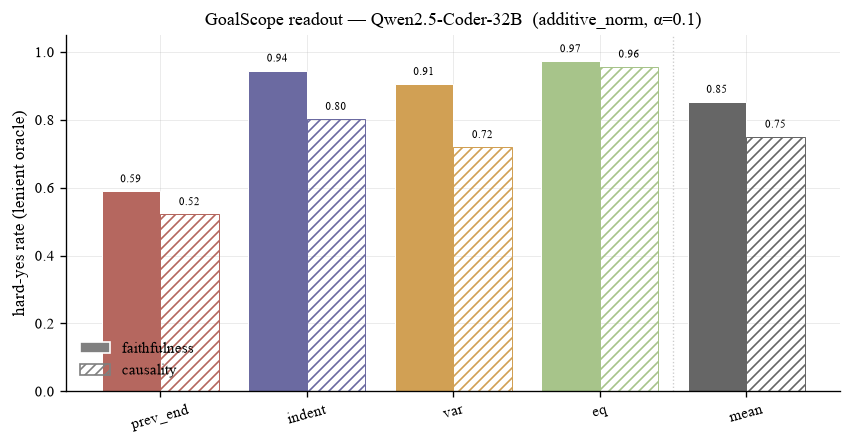

In [2]:
# grouped bars: per pivot + OVERALL, faithfulness (solid) vs causality (hatched)
cats=ANCHORS+['mean']  # mean over pre-impl pivots (no first_impl)
fig, ax = plt.subplots(figsize=(7.2,3.8))
x=np.arange(len(cats)); w=0.4
faith=[hy('faithfulness',a) for a in ANCHORS]+[np.mean([hy('faithfulness',a) for a in ANCHORS])]
caus =[hy('causality',a)    for a in ANCHORS]+[np.mean([hy('causality',a) for a in ANCHORS])]
cols=[F.PIVOT_COLOR[a] for a in ANCHORS]+['#666666']  # per-pivot colours (poster palette); OVERALL grey
for xi,c_ in enumerate(cols):
    ax.bar(xi-w/2, faith[xi], w, **F.metric_kw('faithfulness', c_))
    ax.bar(xi+w/2, caus[xi],  w, **F.metric_kw('causality',    c_))
for xi,(a,b) in enumerate(zip(faith,caus)):
    ax.text(xi-w/2, a+.02, f'{a:.2f}', ha='center', va='bottom', fontsize=6.5)
    ax.text(xi+w/2, b+.02, f'{b:.2f}', ha='center', va='bottom', fontsize=6.5)
ax.set_xticks(x); ax.set_xticklabels(cats, rotation=15)
ax.set_ylabel('hard-yes rate (lenient oracle)'); ax.set_ylim(0,1.05)
ax.set_title(f'GoalScope readout — {MODEL.replace("-Instruct","")}  (additive_norm, \u03b1=0.1)')
ax.axvline(len(ANCHORS)-0.5, color='#ccc', lw=.8, ls=':')
ax.legend(handles=F.metric_legend_handles(), frameon=False, loc='lower left')
fig.tight_layout(); print('saved', F.save_fig(fig, GROUP, 'faithfulness_vs_causality')); plt.show()

      GoalScope hard_yes — Qwen2.5-Coder-32B-Instruct       
                   (additive_norm, a=0.1)                   
┏━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃ metric       ┃ prev_end ┃ indent ┃   var ┃    eq ┃  mean ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ faithfulness │    0.589 │  0.945 │ 0.905 │ 0.972 │ 0.853 │
│ causality    │    0.522 │  0.802 │ 0.719 │ 0.957 │ 0.750 │
└──────────────┴──────────┴────────┴───────┴───────┴───────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/goalscope_eval/goalscope_hardyes.tex


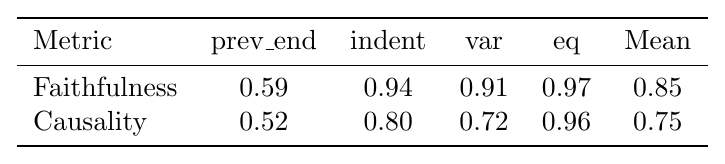

In [3]:
import numpy as np
# table + .tex
t=Table(title=f'GoalScope hard_yes — {MODEL} (additive_norm, a=0.1)')
t.add_column('metric'); [t.add_column(a, justify='right') for a in ANCHORS]; t.add_column('mean', justify='right')
for mode in ['faithfulness','causality']:
    t.add_row(mode, *[f'{hy(mode,a):.3f}' for a in ANCHORS], f"{np.mean([hy(mode,a) for a in ANCHORS]):.3f}")
rich_print(t)
hdr=' & '.join(['Metric']+[a.replace('_','\\_') for a in ANCHORS]+['Mean'])
body=[]
for mode in ['faithfulness','causality']:
    body.append(mode.title()+' & '+' & '.join(f'{hy(mode,a):.2f}' for a in ANCHORS)+f" & {np.mean([hy(mode,a) for a in ANCHORS]):.2f}")
tex='\\begin{tabular}{l'+'c'*(len(ANCHORS)+1)+'}\n\\toprule\n'+hdr+' \\\\\n\\midrule\n'+' \\\\\n'.join(body)+' \\\\\n\\bottomrule\n\\end{tabular}'
print('wrote', F.save_table(tex, GROUP, 'goalscope_hardyes'))
img=F.render_latex_table(tex); img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')